In [1]:
import jax
import os

# # Avoid OOM errors
# os.environ["XLA_PYTHON_CLIENT_MEM_FRACTION"]=".66"
# # os.environ["XLA_PYTHON_CLIENT_PREALLOCATE"]="false"
# print(f"JAX backend: {jax.default_backend()}")

If you don't set the GPU memory allocation, then you can accidentally run out of memory. Sometimes GPU usage is persistant because notebooks, I think.

In [2]:
import sys
sys.path.append("../")

%load_ext autoreload
%autoreload 2

import pulse_simulator as ps

/Users/katesmith/Documents/PROF/repos/xtalk-robust-gates/xtalk/lib/python3.11/site-packages/qiskit_dynamics/dispatch/backends/jax.py:34: UserWarning: The functionality in the perturbation module of Qiskit Dynamics requires a JAX version <= 0.4.6, due to a bug in JAX versions > 0.4.6. For versions 0.4.4, 0.4.5, and 0.4.6, using the perturbation module functionality requires setting os.environ['JAX_JIT_PJIT_API_MERGE'] = '0' before importing JAX or Dynamics.
  warnings.warn(


In [3]:
from datetime import datetime
import functools
import itertools
import logging
import numpy as np
import pickle as pkl
import qiskit as qk
from qiskit import pulse
import qiskit_aer
import qiskit.providers.fake_provider as qk_fp
import qiskit_dynamics as qk_d
import qutip as qt
import re 
from scipy.integrate import simpson
from scipy.linalg import sqrtm, expm
from tqdm import tqdm
import warnings

import matplotlib.pyplot as plt

In [4]:
Units = 1e9

# Undo units
GHz = 1 / Units
MHz = 1e3 / Units
μs = Units / 1e3
ns = Units

backend = qk_fp.FakeManila()
dt = backend.configuration().dt * ns
desired_1qb_duration = 225  # dt
desired_2qb_duration = 225 * 4  # dt

# Gate time in SI units (granularity restriction)
duration_1qb = ps.qiskit_closest_multiple_of_16(desired_1qb_duration * dt / ns, backend)
duration_2qb = ps.qiskit_closest_multiple_of_16(desired_2qb_duration * dt / ns, backend)

# Pulses

We now have a pair of identity gates.

Adjusting X1 to amplitude 0.20078359553005384
Adjusting X2 to amplitude 0.2029490387398391
Adjusting SX1 to amplitude 0.20052729286337825
Adjusting SX2 to amplitude 0.20248564954832834
Adjusting I1 to amplitude 0.2016346225391911


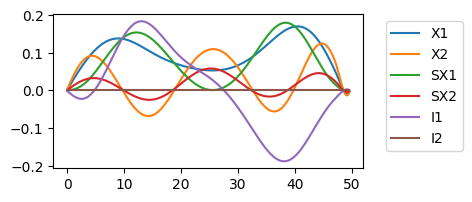

In [5]:
# Load shapes
fname = "../pico-pulses/saved-pulses-2024-02-16/a_single_qubit_gateset_R1e-5.csv"
knames = ["X1", "X2", "SX1", "SX2", "I1"]
pico_a = {k: v for k, v in zip(knames, ps.from_csv(fname))}
# pico_a["I2"] = np.zeros(pico_a["I1"].shape)

# The initial run takes awhile to construct the symbolic pulse shapes
x_gates = {}
for k, v in pico_a.items():
    x_gates[k] = ps.scalable_symbolic_pulse(duration_1qb, v, f"custom-{k}")

# Calibrate the robust X gates
ts = np.arange(0, dt * duration_1qb, dt)
fig, ax = plt.subplots(1, 1, figsize=[4,2])
cal_x_gates = {}
# Only hit the first 4 gates
cal_values = [1.5 * np.pi, 0.5 * np.pi, 1.25 * np.pi, 0.25 * np.pi]
cal_amps = []
for θ, (k, v) in zip(cal_values, x_gates.items()):
    amp = ps.get_amplitude_for_rotation(θ, ps.get_samples(v).real, dt)
    cal_amps.append(amp)
    print(f"Adjusting {k} to amplitude {amp}")
    cal_x_gates[k] = qk.pulse.ScalableSymbolicPulse(
        pulse_type=f"{k}-calibrated",
        duration=duration_1qb,
        amp=amp,
        angle=0.0,
        limit_amplitude=False,
        envelope=v.envelope,
    )
    ax.plot(ts, ps.get_samples(cal_x_gates[k]).real, label=k)

k = "I1"
v = x_gates[k]
amp = np.median(cal_amps)
print(f"Adjusting {k} to amplitude {amp}")
cal_x_gates[k] = qk.pulse.ScalableSymbolicPulse(
        pulse_type=f"{k}-calibrated",
        duration=duration_1qb,
        amp=amp,
        angle=0.0,
        limit_amplitude=False,
        envelope=v.envelope,
)
ax.plot(ts, ps.get_samples(cal_x_gates[k]).real, label=k)

k = "I2"
v = ps.zero_envelope(duration_1qb)
cal_x_gates[k] = qk.pulse.ScalableSymbolicPulse(
        pulse_type=f"{k}-calibrated",
        duration=duration_1qb,
        amp=0.0,
        angle=0.0,
        limit_amplitude=False,
        envelope=v.envelope,
)
ax.plot(ts, ps.get_samples(cal_x_gates[k]).real, label=k)

# Add legend
ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left')

# Calibrate the default X gates
default_gates = {}
for k in pico_a.keys():
    if "SX" in k:
        default_gates[k] = ps.gaussian_envelope(duration_1qb, dt=dt, angle=np.pi / 4)
    elif "X" in k:
        default_gates[k] = ps.gaussian_envelope(duration_1qb, dt=dt, angle=np.pi / 2)
    elif "I" in k:
        default_gates[k] = ps.zero_envelope(duration_1qb)
    else:
        raise ValueError(f"Unknown gate {k}")
default_gates["I2"] = ps.zero_envelope(duration_1qb)


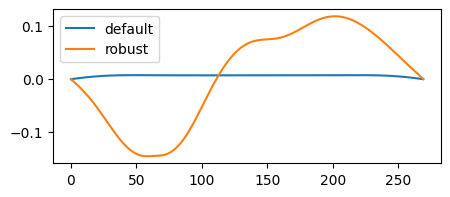

In [6]:
# Load shapes
def fname(k):
    return f"../pico-pulses/saved-pulses-2024-01-16/a_two_qubit_{k}.csv"
knames = ["default", "robust"]
pico2_a = {k: ps.from_csv(fname(k))[0] for k in knames}

# Less precise about optimization than before...
fig, ax = plt.subplots(figsize=[5, 2])
for k, v in pico2_a.items():
    ax.plot(v, label=k)
ax.legend()

# Downsample the pulse to make construction faster
cr_gates = {}
for k, v in pico2_a.items():
    cr_gates[k] = ps.scalable_symbolic_pulse(
        duration_2qb,
        ps.resample(51, v, keep_step=False),
        f"cr-{k}"
    )

# Add positive and negative rotations to gateset
cal_cr_gates = {}
cal_values = [0.125 * np.pi, 0.125 * np.pi]
for θ, (k, v) in zip(cal_values, cr_gates.items()):
    amp = ps.get_amplitude_for_rotation(θ, ps.get_samples(v).real, dt)
    cal_cr_gates[k] = {
        "+": qk.pulse.ScalableSymbolicPulse(
            pulse_type=f"{k}-calibrated+amp",
            duration=duration_2qb,
            amp=amp,
            angle=0.0,
            limit_amplitude=False,
            envelope=v.envelope,
        ),
        "-": qk.pulse.ScalableSymbolicPulse(
            pulse_type=f"{k}-calibrated-amp",
            duration=duration_2qb,
            amp=-amp,
            angle=0.0,
            limit_amplitude=False,
            envelope=v.envelope,
        ),
    }

# Circuits

In [7]:
# Set the parameters globally for the model
N = 4  # number of spins
hz = 1.0 * 2 * np.pi  # magnetic field along z
Jx = 1.0 * 2 * np.pi  # Coupling along x
Δt = 0.05  # time step for integration


def create_initial_state(qr, cr):
    '''
    Creates the initial state for the experiment.
    Here we would like to prepare the |+>|+>|+>|+> state.
    '''
    circ = qk.QuantumCircuit(qr, cr)
    [circ.h(qr[i]) for i in range(qr.size)]
    return circ


def rxx(circ, θx, q1, q2):
    '''
    Implements the exp(-i theta/2 sx_1 sx_2) gate.
    '''
    circ.cx(q1, q2)
    circ.rx(θx, q1)
    circ.cx(q1, q2)
    return circ


def first_order_Trotter_unitary(circ, Δt, barrier=False):
    '''
    Applies a Unitary for a single time step U(Δt) using first-order trotter expansion to the input quantum circuit.
    input : circ is a quantum circuit
    output : circ-U(Δt)-
    '''
    # Layer A: coupling XX between n and n+1
    # Induce parallel CR gates
    if barrier:
        circ.barrier()
    for p in range(0, circ.num_qubits - 1, 2):
        circ = rxx(circ, Jx * Δt, circ.qubits[p], circ.qubits[p + 1])
    if barrier:
        circ.barrier()
    for p in range(1, circ.num_qubits - 1, 2):
        circ = rxx(circ, Jx * Δt, circ.qubits[p], circ.qubits[p + 1])

    #  Alt., a naive loop will apply XX rotations sequentially, failing to stack.
    # for p in range(0, circ.num_qubits - 1):
    #     circ = rxx(circ, Jx * Δt, circ.qubits[p], circ.qubits[p + 1])

    # Layer B: on-site Z
    for p in range(circ.num_qubits):    
        circ.rz(hz*Δt, circ.qubits[p])

    return circ


def second_order_Trotter_unitary(circ, Δt, barrier=False):
    '''
    Applies a Unitary for a single time step U(Δt) using second-order trotter expansion to the input quantum circuit.
    input : circ is a quantum circuit
    output : circ-U(Δt)-
    '''
    # Layer 2: on-site Z (half)
    for p in range(circ.num_qubits):
        circ.rz(hz * Δt / 2, circ.qubits[p])
 
    # Layer 1: coupling XX between n and n+1
    # Induce parallel structure (and symmetry)
    for p in range(1, circ.num_qubits - 1, 2):
        circ = rxx(circ, Jx * Δt / 2, circ.qubits[p], circ.qubits[p+1])
    # NOTE: Add barriers to separate the parallel section
    if barrier:
        circ.barrier()
    for p in range(0, circ.num_qubits - 1, 2):
        circ = rxx(circ, Jx * Δt, circ.qubits[p], circ.qubits[p+1])
    if barrier:
        circ.barrier()
    for p in range(1, circ.num_qubits - 1, 2):
        circ = rxx(circ, Jx * Δt / 2, circ.qubits[p], circ.qubits[p+1])

    # Layer 2: on-site Z (half)
    for p in range(circ.num_qubits):
        circ.rz(hz * Δt / 2, circ.qubits[p])
    return circ

In [8]:
# """
# Test the circuit with identity gates inserted
# """


registers = [0, 1, 2, 3]

qr = qk.QuantumRegister(len(registers))
cr = qk.ClassicalRegister(len(registers))
circ = create_initial_state(qr, cr)
circ = second_order_Trotter_unitary(circ, Δt)

mb = ps.MomentBuilder()
my_moments = mb.build_moments(circ)

# Temporary fix
my_moments = ps.uncolor_moments(my_moments)

# # Add in explicit identity gates
# for m in my_moments:
#     if ps.get_moment_case(m) == "single":
#         missing = [i for i in range(len(registers)) if i not in m.keys()]
#         for k in missing:
#             m[k] = "I1" if k % 2 == 0 else "I2"

In [9]:
# Aside: Caught this bug!
[(i,j) for i,j in zip(ps.color_moments(ps.uncolor_moments(mb.build_moments(circ))), mb.build_moments(circ)) if i != j]

[({(0, 1): 'ECR1', (2, 3): 'ECR1'}, {(0, 1): 'ECR2', (2, 3): 'ECR1'}),
 ({(0, 1): 'ECR1', (2, 3): 'ECR1'}, {(0, 1): 'ECR2', (2, 3): 'ECR1'})]

/Users/katesmith/Documents/PROF/repos/xtalk-robust-gates/xtalk/lib/python3.11/site-packages/qiskit/visualization/circuit/matplotlib.py:266: FutureWarning: The default matplotlib drawer scheme will be changed to "iqp" in a following release. To silence this warning, specify the current default explicitly as style="clifford", or the new default as style="iqp".
  self._style, def_font_ratio = load_style(self._style)


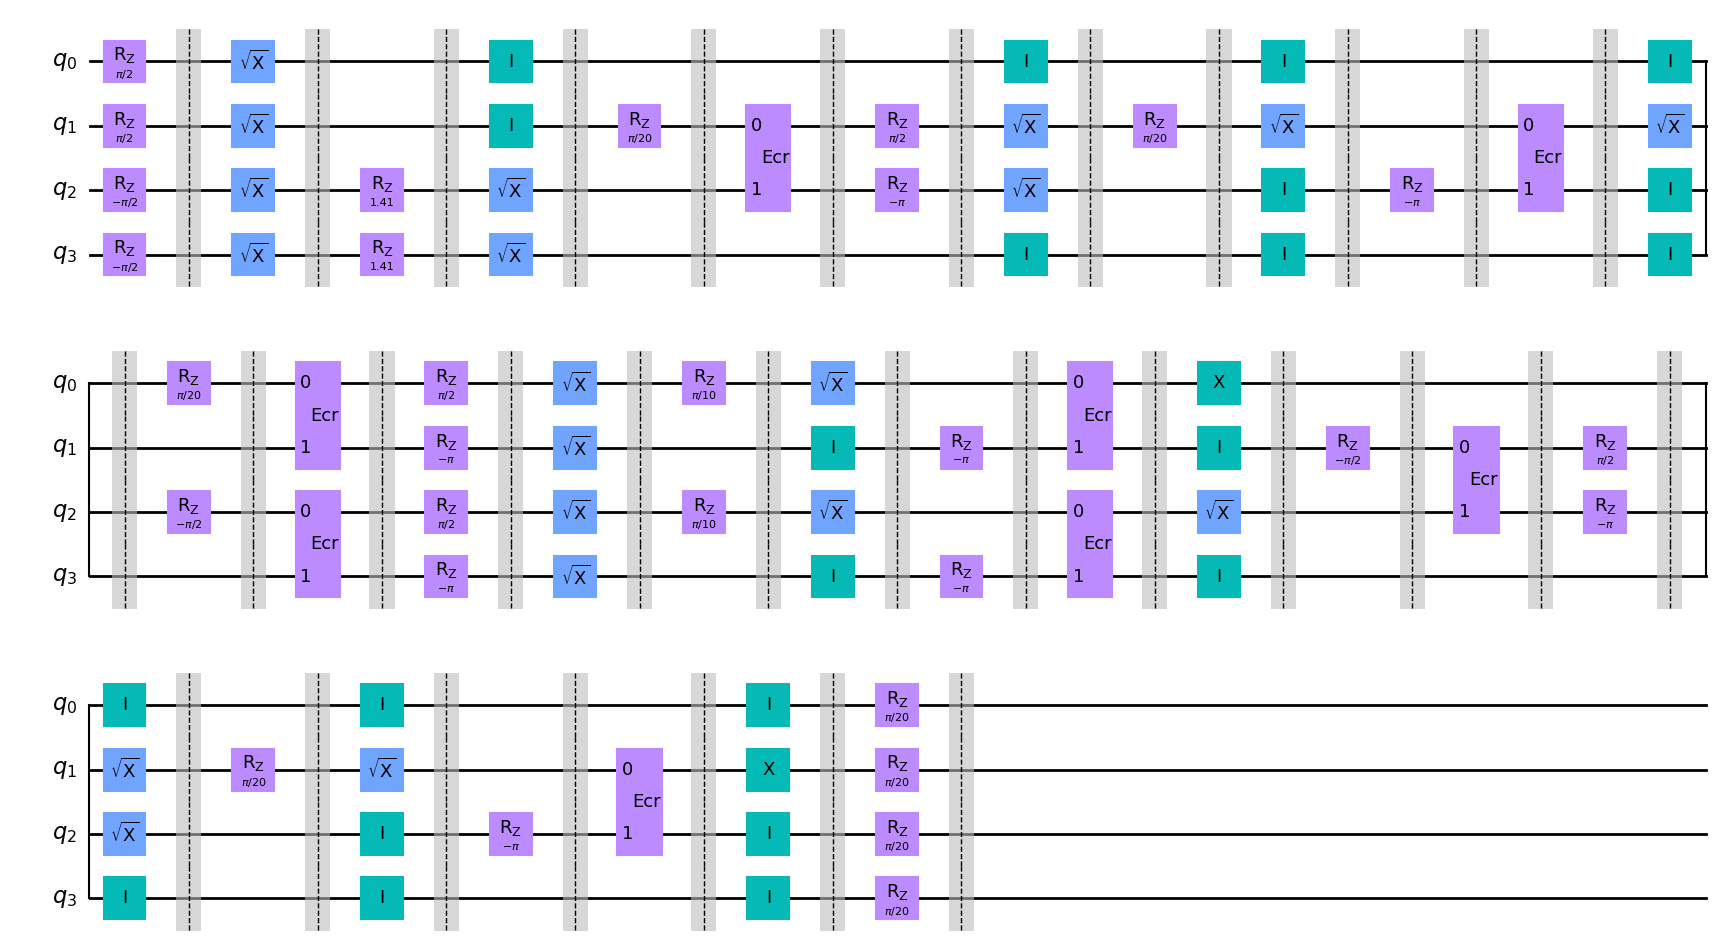

In [10]:
circ = ps.build_circuit(my_moments, registers, insert_identities=True, includes_coloring=False, barriers=True)
circ.draw('mpl')

In [11]:
sched = ps.build_pulse_schedule(
    my_moments,
    qubit_gates=default_gates,
    cr_gates=cal_cr_gates['default'],
    registers=registers,
    backend=backend,
    name="hamiltonian-simulation",
    dt=dt
)

robust_sched = ps.build_pulse_schedule(
    my_moments,
    qubit_gates=cal_x_gates,
    cr_gates=cal_cr_gates['robust'],
    registers=registers,
    backend=backend,
    name="hamiltonian-simulation",
    dt=dt
)

mix_sched = ps.build_pulse_schedule(
    my_moments,
    qubit_gates=default_gates,
    cr_gates=cal_cr_gates['robust'],
    registers=registers,
    backend=backend,
    name="hamiltonian-simulation",
    dt=dt,
    insert_identities=True
)

# Check durations
assert robust_sched.duration == sched.duration

# Would be nice to disable phase channels when plotting
# sched.draw()

Building schedule with 32 moments. 
	 Qubit gateset: dict_keys(['X1', 'X2', 'SX1', 'SX2', 'I1', 'I2'])
	 CR gateset: dict_keys(['+', '-'])
	 Registers: [0, 1, 2, 3]
	 Insert identities: True
Building schedule with 32 moments. 
	 Qubit gateset: dict_keys(['X1', 'X2', 'SX1', 'SX2', 'I1', 'I2'])
	 CR gateset: dict_keys(['+', '-'])
	 Registers: [0, 1, 2, 3]
	 Insert identities: True
Building schedule with 32 moments. 
	 Qubit gateset: dict_keys(['X1', 'X2', 'SX1', 'SX2', 'I1', 'I2'])
	 CR gateset: dict_keys(['+', '-'])
	 Registers: [0, 1, 2, 3]
	 Insert identities: True


### Build QV circuit

/Users/katesmith/Documents/PROF/repos/xtalk-robust-gates/xtalk/lib/python3.11/site-packages/qiskit/visualization/circuit/matplotlib.py:266: FutureWarning: The default matplotlib drawer scheme will be changed to "iqp" in a following release. To silence this warning, specify the current default explicitly as style="clifford", or the new default as style="iqp".
  self._style, def_font_ratio = load_style(self._style)


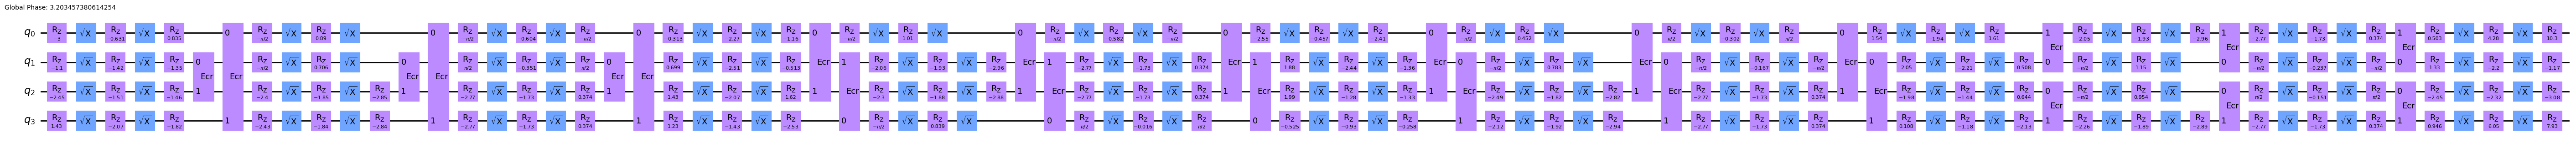

In [38]:
import qiskit 

registers = [0, 1, 2, 3]


qv = qiskit.circuit.library.QuantumVolume(num_qubits=4, depth=None, seed=0, classical_permutation=True) 

  

transpiled_qv = qiskit.transpile(qv, basis_gates=['ecr','sx','x','rz','id']) 
transpiled_qv.draw("mpl", fold=-1)

In [39]:
qv_moments = mb.build_moments(transpiled_qv) 
qv_moments = ps.uncolor_moments(qv_moments)


qv_moments 

[{0: 1.4334233648698254,
  1: -1.09763757081548,
  2: -2.4478623389354217,
  3: -2.9961222076352163},
 {0: 'SX', 1: 'SX', 2: 'SX', 3: 'SX'},
 {0: -2.0669804394426583,
  1: -1.4216124215469392,
  2: -1.5148818055377467,
  3: -0.6305503005973243},
 {0: 'SX', 1: 'SX', 2: 'SX', 3: 'SX'},
 {1: -1.3485939078829947, 2: -1.4613856265130565},
 {(1, 2): 'ECR'},
 {1: -1.5707963267948966, 2: -2.4039471880539063},
 {1: 'SX', 2: 'SX'},
 {1: 0.705589678843324, 2: -1.8505837935172789},
 {1: 'SX', 2: 'SX'},
 {2: -2.846589150278459},
 {(1, 2): 'ECR'},
 {1: 1.5707963267948966, 2: -2.767250088045947},
 {1: 'SX', 2: 'SX'},
 {1: -0.3509477047494052, 2: -1.7257606517825632},
 {1: 'SX', 2: 'SX'},
 {1: 1.5707963267948966, 2: 0.37434256554384504},
 {(1, 2): 'ECR'},
 {1: 1.8427370967106702, 2: -1.6163721481954587},
 {1: 'SX', 2: 'SX'},
 {1: -1.2766497874020768, 2: -2.6364852336207925},
 {1: 'SX', 2: 'SX'},
 {2: 3.0551345552332325, 3: 0.8345591561644401},
 {2: 'SX', 3: 'SX'},
 {0: 2.894366340619519,
  1: -1.00355

In [40]:
sched = ps.build_pulse_schedule(
    qv_moments,
    qubit_gates=default_gates,
    cr_gates=cal_cr_gates['default'],
    registers=registers,
    backend=backend,
    name="hamiltonian-simulation",
    dt=dt
)

robust_sched = ps.build_pulse_schedule(
    qv_moments,
    qubit_gates=cal_x_gates,
    cr_gates=cal_cr_gates['robust'],
    registers=registers,
    backend=backend,
    name="hamiltonian-simulation",
    dt=dt
)

mix_sched = ps.build_pulse_schedule(
    qv_moments,
    qubit_gates=default_gates,
    cr_gates=cal_cr_gates['robust'],
    registers=registers,
    backend=backend,
    name="hamiltonian-simulation",
    dt=dt,
    insert_identities=True
)

# Check durations
assert robust_sched.duration == sched.duration

# Would be nice to disable phase channels when plotting
# sched.draw()

Building schedule with 135 moments. 
	 Qubit gateset: dict_keys(['X1', 'X2', 'SX1', 'SX2', 'I1', 'I2'])
	 CR gateset: dict_keys(['+', '-'])
	 Registers: [0, 1, 2, 3]
	 Insert identities: True
Building schedule with 135 moments. 
	 Qubit gateset: dict_keys(['X1', 'X2', 'SX1', 'SX2', 'I1', 'I2'])
	 CR gateset: dict_keys(['+', '-'])
	 Registers: [0, 1, 2, 3]
	 Insert identities: True
Building schedule with 135 moments. 
	 Qubit gateset: dict_keys(['X1', 'X2', 'SX1', 'SX2', 'I1', 'I2'])
	 CR gateset: dict_keys(['+', '-'])
	 Registers: [0, 1, 2, 3]
	 Insert identities: True


In [41]:
my_moments = qv_moments

# Models

In [42]:
scale = 1.0


# Set registers above with circuit
# The rest is automatic
# ===================== 

# NOTE: If the Rabi rates are True, you have to calibrate!
cvars = ps.backend_simulation_vars(backend, rabi=False, units=Units)

# Change T1 and T2 to match Eagle processors like Sherbrooke
for k, v in cvars.items():
    if "t1" in k:
        cvars[k] = 250 / μs * ns
    if "t2" in k:
        cvars[k] = 150 / μs * ns

# Carrier frequencies of each control line
# NOTE: We won't use carriers in this example
carriers = ps.backend_carriers(backend, cvars)

# Partially compile model functions with parameters
# =====
H_rx = functools.partial(
    ps.rx_model,
    registers=registers,
    backend=backend,
    variables=cvars,
    rotating_frame=True,
)

H_rz = functools.partial(
    ps.rz_model,
    registers=registers,
    backend=backend,
)

H_cr = functools.partial(
    ps.cross_resonance_model,
    registers=registers,
    backend=backend,
    variables=cvars,
    model_name="Toy",
)

A_decay = functools.partial(ps.qubit_decay_model, registers=registers, variables=cvars)

edges = ps.backend_edges(backend) #[1:-1]
print(f"Edges: {edges}")
H_xtalk = scale * ps.crosstalk_model(registers, edges, cvars)

# Create a system model
# =====
H_drift = 0.0
Hs_control = []
Hs_channels = []
As_static = []
for qubit in registers:
    # Single qubit terms
    Hj_drift, Hjs_control, Hjs_channel = H_rx(qubit)
    Hj_phase, Hj_phase_ch = H_rz(qubit)
    Ajs_static = A_decay(qubit)

    H_drift += Hj_drift
    Hs_control += Hjs_control + [Hj_phase]
    Hs_channels += Hjs_channel + [Hj_phase_ch]
    As_static += Ajs_static

    # Two qubit with ring connectivity
    if qubit < len(registers) - 1:
        control, target = qubit, qubit + 1
        
        # Get both directions
        for pair in [(control, target), (target, control)]:
            Hj_drift, Hjs_control, Hjs_channel = H_cr(pair)
            H_drift += Hj_drift
            Hs_control += Hjs_control
            Hs_channels += Hjs_channel

# Some models may repeat control channels
# NOTE: This actually really matters! Repeat channels mess things up.
Hs_channels, indices = np.unique(Hs_channels, return_index=True)
Hs_control = [Hs_control[i] for i in indices]

# For RWA / Rotating frame
# NOTE: We won't use carriers in this example
# =====
registered_carriers = {c: 0 for c in Hs_channels}
cutoff_freq = None

# registered_carriers = {c: carriers[c] for c in Hs_channels}
# cutoff_freq = 2 * np.mean(list(registered_carriers.values()))

Edges: [(0, 1), (1, 2), (2, 3), (3, 4)]


# Solvers

In [43]:
# Models already in the rotating frame
# =====

solver_r0 = qk_d.Solver(
    static_hamiltonian=None,
    hamiltonian_operators=Hs_control,
    hamiltonian_channels=Hs_channels,
    # static_dissipators=As_static,
    rotating_frame=None,
    rwa_cutoff_freq=None,
    channel_carrier_freqs=registered_carriers,
    dt=dt
)

solver_r = qk_d.Solver(
    static_hamiltonian=None,
    hamiltonian_operators=Hs_control,
    hamiltonian_channels=Hs_channels,
    static_dissipators=As_static,
    rotating_frame=None,
    rwa_cutoff_freq=None,
    channel_carrier_freqs=registered_carriers,
    dt=dt
)

solver_rx0 = qk_d.Solver(
    static_hamiltonian=H_xtalk,
    hamiltonian_operators=Hs_control,
    hamiltonian_channels=Hs_channels,
    # static_dissipators=As_static,
    rotating_frame=None,
    rwa_cutoff_freq=None,
    channel_carrier_freqs=registered_carriers,
    dt=dt
)

solver_rx = qk_d.Solver(
    static_hamiltonian=H_xtalk,
    hamiltonian_operators=Hs_control,
    hamiltonian_channels=Hs_channels,
    static_dissipators=As_static,
    rotating_frame=None,
    rwa_cutoff_freq=None,
    channel_carrier_freqs=registered_carriers,
    dt=dt
)

# Unitary simulations

In [44]:
# measure after each non-phase moment
measure_times = dt * np.cumsum(
    ps.durations_of_moments(my_moments, cal_x_gates, cal_cr_gates['default'])
)[[ps.get_moment_case(m) != "phase" for m in my_moments]]
# and at the end time...
measure_times = np.append(measure_times, sched.duration * dt)


# targets at measure times
Uts = []
for i, m in enumerate(my_moments):
    if ps.get_moment_case(m) != "phase":
        Uts.append(ps.build_operator(my_moments[0:i+1], registers))
# and at the end time...
Uts.append(qk.quantum_info.Operator(ps.build_circuit(my_moments, registers)))

# Target
target = Uts[-1]

In [45]:
# measure after each 2qb moment
measure_times = dt * np.cumsum(
    ps.durations_of_moments(my_moments, cal_x_gates, cal_cr_gates['default'])
)[[ps.get_moment_case(m) == "ecr" for m in my_moments]]


# targets at measure times
Uts = []
for i, m in enumerate(my_moments):
    if ps.get_moment_case(m) == "ecr":
        Uts.append(ps.build_operator(my_moments[0:i+1], registers))

In [46]:
print("Case 2: Crosstalk, no decay")

y0 = ps.qiskit_identity_operator(len(registers))

# labels = ["robust (rotary)"]
# all_schedules = [robust_sched]

# labels = ["robust (rotary)",  "default (rotary)"]
# all_schedules = [robust_sched, mix_sched]

labels = ["default", "robust (rotary)", "default (rotary)"]
all_schedules = [sched, robust_sched, mix_sched]


# ==========

solver_rx0.model.evaluation_mode = "sparse"
res_x0 = solver_rx0.solve(
    t_span=[0.0, sched.duration * dt],
    t_eval=measure_times,
    y0=y0,
    signals=all_schedules,
    atol=1e-9,
    rtol=1e-9,
    method="jax_odeint",
)

# Compute fidelity (we can use our circuit to compute the target)
target = qk.quantum_info.Operator(ps.build_circuit(my_moments, registers))

for i, ell in enumerate(labels):
    print(f"\tInfidelity of {ell}: ", 1 - qk.quantum_info.process_fidelity(res_x0[i].y[-1], target))

Case 2: Crosstalk, no decay


 -2.59000194e-07 -2.51360482e-07 -2.40657259e-07 -2.35156403e-07
 -2.20971180e-07 -2.15296750e-07 -2.04060691e-07 -1.90635753e-07
 -1.85608294e-07 -1.75952158e-07 -1.67092001e-07 -1.42268649e-07]
 -2.62250302e-07 -2.58625224e-07 -2.44426742e-07 -2.35574039e-07
 -2.21507836e-07 -2.20544598e-07 -2.09537101e-07 -1.94170574e-07
 -1.87103284e-07 -1.80115210e-07 -1.70963024e-07 -1.47851280e-07]
 -2.52732034e-07 -2.45590531e-07 -2.32400363e-07 -2.23894295e-07
 -2.11621020e-07 -2.10058976e-07 -1.96967390e-07 -1.83327790e-07
 -1.76864186e-07 -1.68988437e-07 -1.59640900e-07 -1.35800816e-07]


	Infidelity of default:  0.9978133641969117
	Infidelity of robust (rotary):  0.9988275352901855
	Infidelity of default (rotary):  0.9986375790763714


 -1.39998768e-08]
 -2.77851971e-08 -2.51432114e-08 -2.25974708e-08 -2.04633091e-08
 -1.85487431e-08 -1.65396942e-08 -1.44124663e-08 -1.42284974e-08
 -1.37206595e-08]
 -4.02853158e-08 -3.79617818e-08 -3.22149544e-08 -3.02319994e-08
 -2.70597153e-08 -2.53556629e-08 -2.24820664e-08 -2.01387635e-08
 -1.93072631e-08 -1.69314454e-08 -1.49483523e-08 -1.43519367e-08]
 -6.12841510e-08 -5.79752706e-08 -5.23920367e-08 -4.68521497e-08
 -4.55953632e-08 -4.29430661e-08 -4.03961869e-08 -3.55553023e-08
 -3.24809039e-08 -2.98786842e-08 -2.79905944e-08 -2.38588494e-08]
 -6.88753962e-08 -6.43618069e-08 -5.88530055e-08 -5.56144410e-08
 -5.40067582e-08 -4.95212163e-08 -4.69243814e-08 -4.25886533e-08
 -3.91313671e-08 -3.80365350e-08 -3.42507253e-08 -3.18806380e-08]
 -7.73499568e-08 -7.17073587e-08 -6.63425768e-08 -6.20750604e-08
 -5.71882564e-08 -5.39842088e-08 -4.92370012e-08 -4.69681807e-08
 -4.20218453e-08 -4.15331253e-08 -3.88030122e-08 -3.53395893e-08]
 -8.60912314e-08 -7.95434354e-08 -7.43856850e-08 -

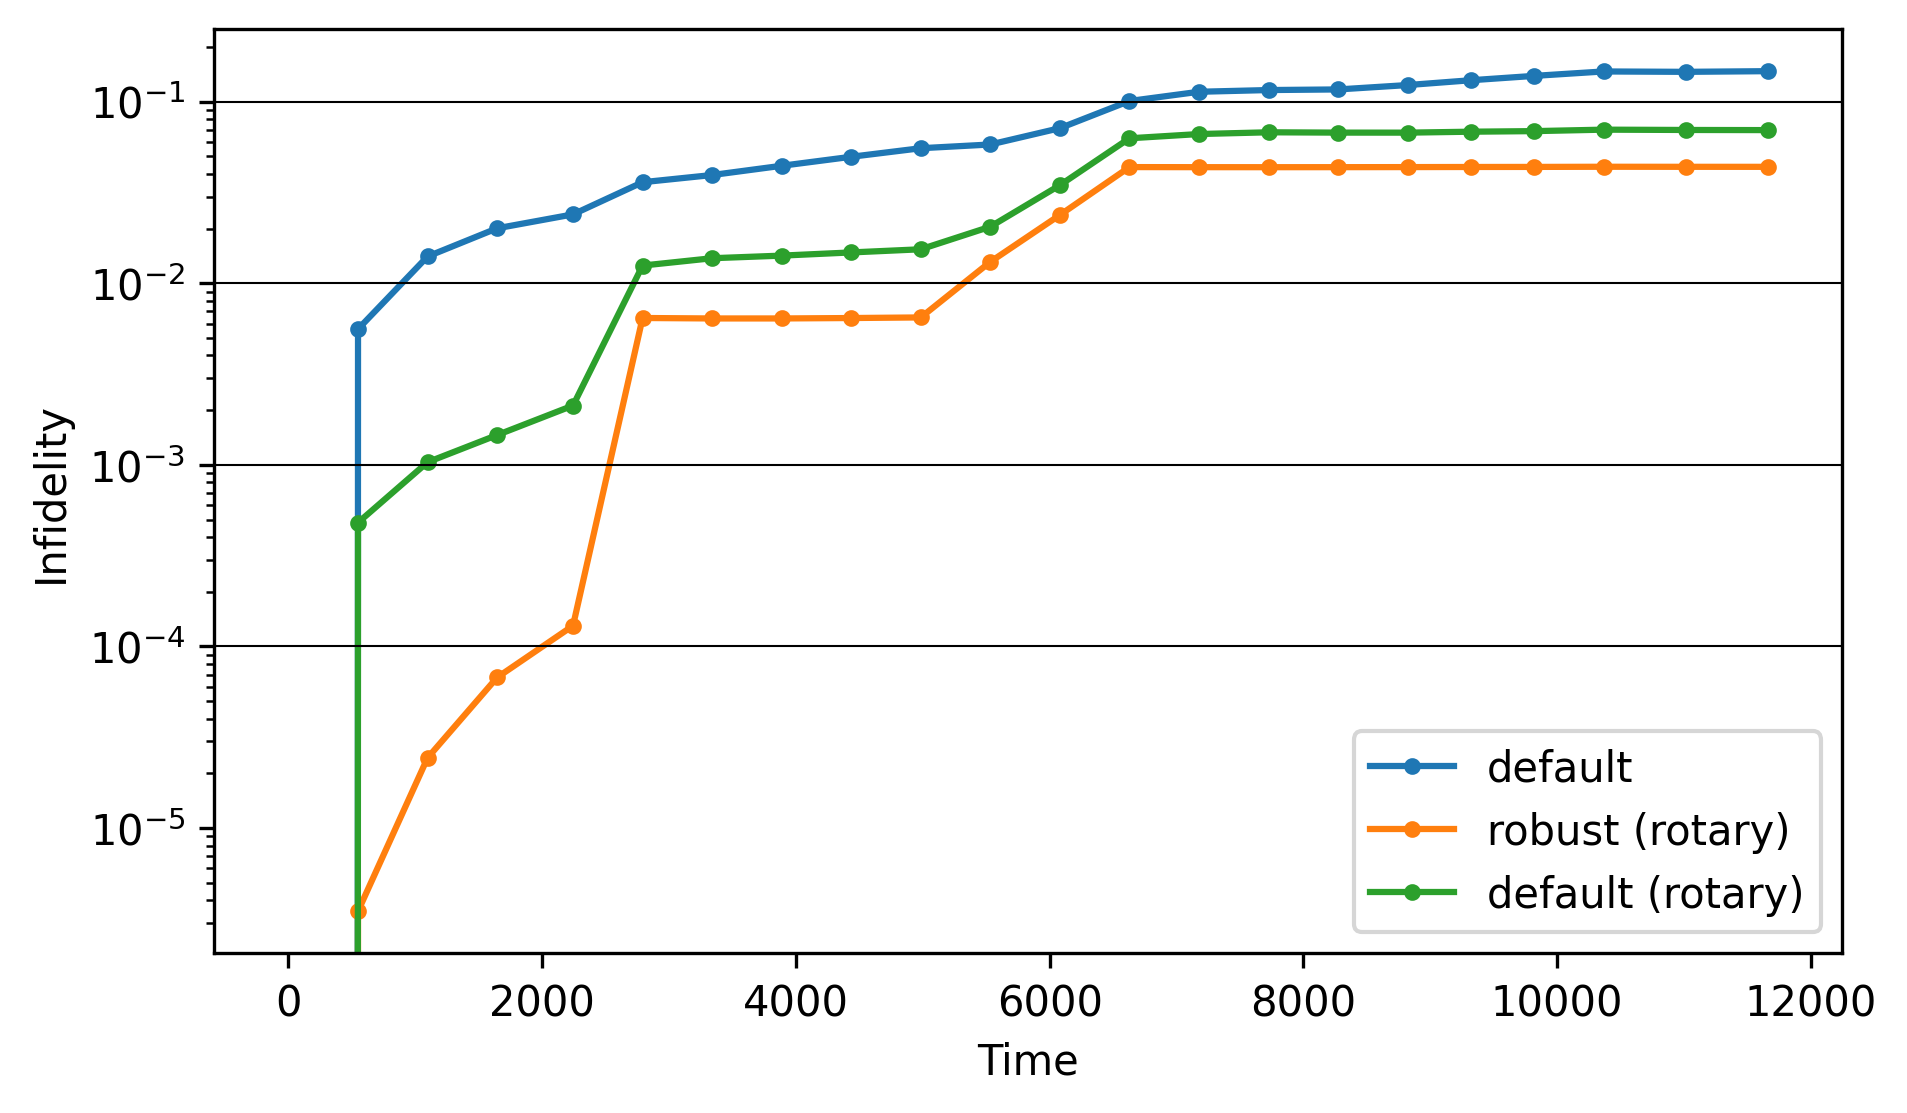

In [47]:
fig, axes = plt.subplots(1, figsize=[7, 4], dpi=300)
axes = axes if isinstance(axes, np.ndarray) else [axes]
# axes[0].set_title("Hamiltonian simulation: Crosstalk, No decoherence", loc='left')


for iax in range(1):
    ax = axes[iax]

    for i, res in enumerate(res_x0):
        infids = [0]
        # if labels[i] == "default":
        #     continue
        for r, t in zip(res.y, Uts):
            infids.append(1 - qk.quantum_info.process_fidelity(qk.quantum_info.Operator(r), qk.quantum_info.Operator(t)))
        ax.plot(np.hstack([0, *measure_times]), infids, label=labels[i], marker=".")

    ax.axhline(0.1, color="black", linestyle="-", lw=0.5)
    ax.axhline(0.01, color="black", linestyle="-", lw=0.5)
    ax.axhline(0.001, color="black", linestyle="-", lw=0.5)
    ax.axhline(0.0001, color="black", linestyle="-", lw=0.5)
    # ax.axhline(1e-10, color="black", linestyle="-", lw=0.5)


    ax.set_xlabel("Time")
    if iax == 0:
        ax.legend(loc="lower right")
        ax.set_yscale("log")
        # ax.set_ylim([0, .001])
        ax.set_ylabel("Infidelity")
    else:
        ax.set_ylabel("Infidelity")
        ax.legend(loc="upper left")
        ax.set_yscale("linear")



### Plots for layers of Hamiltonian simulation

This is the crosstalk-free sim and plot. We won't need that sim for now.

In [49]:
print("Case 1: No crosstalk, no decay")

y0 = ps.qiskit_identity_operator(len(registers))

solver_r0.model.evaluation_mode = "sparse"
res_0 = solver_r0.solve(
    t_span=[0.0, sched.duration * dt],
    t_eval=[sched.duration * dt],
    y0=y0,
    signals=[sched, robust_sched, mix_sched],
    atol=1e-9,
    rtol=1e-9,
    method="jax_odeint",
)

# Compute fidelity (we can use our circuit to compute the target)
target = ps.build_operator(my_moments, registers)

print(
    "\tInfidelity of default schedule: ",
    1 - qk.quantum_info.process_fidelity(res_0[0].y[-1], target),
)
print(
    "\tInfidelity of robust schedule: ",
    1 - qk.quantum_info.process_fidelity(res_0[1].y[-1], target),
)
print(
    "\tInfidelity of mixed schedule: ",
    1 - qk.quantum_info.process_fidelity(res_0[2].y[-1], target),
)


Case 1: No crosstalk, no decay


 -3.08788951e-07 -2.95062808e-07 -2.70391202e-07 -2.60977725e-07
 -2.51393659e-07 -2.47262073e-07 -2.30308557e-07 -2.23939188e-07
 -2.09963559e-07 -1.97171390e-07 -1.92011854e-07 -1.61151048e-07]
 -3.12791913e-07 -3.00029708e-07 -2.75007217e-07 -2.65981185e-07
 -2.55697148e-07 -2.50664677e-07 -2.34757226e-07 -2.27699031e-07
 -2.15361786e-07 -2.01841526e-07 -1.97840717e-07 -1.67256822e-07]
 -3.01103579e-07 -2.87585025e-07 -2.62090608e-07 -2.53255708e-07
 -2.43446896e-07 -2.39191145e-07 -2.22282537e-07 -2.15734730e-07
 -2.02437612e-07 -1.89652897e-07 -1.84715452e-07 -1.54328070e-07]


	Infidelity of default schedule:  1.1559650417991563e-06
	Infidelity of robust schedule:  0.0004701838704044281
	Infidelity of mixed schedule:  1.247442309448843e-06


 -3.08788951e-07 -2.95062808e-07 -2.70391202e-07 -2.60977725e-07
 -2.51393659e-07 -2.47262073e-07 -2.30308557e-07 -2.23939188e-07
 -2.09963559e-07 -1.97171390e-07 -1.92011854e-07 -1.61151048e-07]
 -5.91906857e-07 -5.75073403e-07 -5.55724348e-07 -5.34993979e-07
 -5.18465879e-07 -5.07107756e-07 -4.86513317e-07 -4.78065999e-07
 -4.66300413e-07 -4.34216187e-07 -4.22546447e-07 -3.83872832e-07]
 -8.62326445e-07 -8.47464081e-07 -8.21468315e-07 -8.05436162e-07
 -7.78413863e-07 -7.70139995e-07 -7.46721181e-07 -7.39499525e-07
 -7.10560871e-07 -6.83980520e-07 -6.59365217e-07 -6.20189362e-07]
 -1.14005895e-06 -1.11697803e-06 -1.09741003e-06 -1.07294767e-06
 -1.05042149e-06 -1.02761031e-06 -1.02399156e-06 -9.77016560e-07
 -9.60241223e-07 -9.34489510e-07 -8.83810564e-07 -8.65621977e-07]
 -1.41817596e-06 -1.39550698e-06 -1.36075348e-06 -1.34659958e-06
 -1.33345772e-06 -1.30825550e-06 -1.27570573e-06 -1.23929960e-06
 -1.21429904e-06 -1.18056305e-06 -1.13268370e-06 -1.07497447e-06]
 -1.69283202e-06 -1.

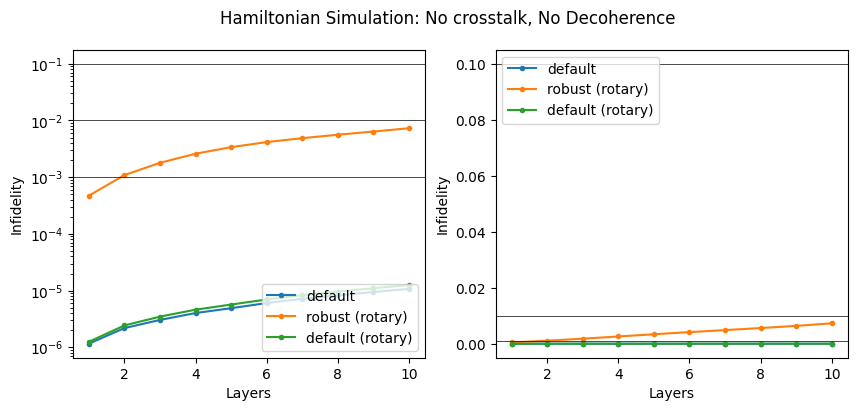

In [50]:
fig, axes = plt.subplots(1, 2, figsize=[10, 4])
fig.suptitle("Hamiltonian Simulation: No crosstalk, No Decoherence")

n = 10
layers = np.arange(1, n + 1)
Uts = list(itertools.accumulate(np.repeat([target], n, axis=0), np.matmul))

for iax in range(2):
    ax = axes[iax]

    for i, r in enumerate(res_0):
        Ufs = itertools.accumulate(np.repeat([r.y[-1]], n, axis=0), np.matmul)
        infids = []
        for r, t in zip(Ufs, Uts):
            infids.append(1 - qk.quantum_info.process_fidelity(qk.quantum_info.Operator(r), qk.quantum_info.Operator(t)))
        ax.plot(layers, infids, label=labels[i], marker=".")

    ax.axhline(0.1, color="black", linestyle="-", lw=0.5)
    ax.axhline(0.01, color="black", linestyle="-", lw=0.5)
    ax.axhline(0.001, color="black", linestyle="-", lw=0.5)

    ax.set_xlabel("Layers")
    if iax == 0:
        ax.legend(loc="lower right")
        ax.set_yscale("log")
        ax.set_ylabel("Infidelity")
    else:
        ax.set_ylabel("Infidelity")
        ax.legend(loc="upper left")
        ax.set_yscale("linear")

This is the plot for the crosstalk example. We're still using that simulation up above.

 -2.59000194e-07 -2.51360482e-07 -2.40657259e-07 -2.35156403e-07
 -2.20971180e-07 -2.15296750e-07 -2.04060691e-07 -1.90635753e-07
 -1.85608294e-07 -1.75952158e-07 -1.67092001e-07 -1.42268649e-07]
 -5.13504731e-07 -4.95726554e-07 -4.86278421e-07 -4.66874056e-07
 -4.54208401e-07 -4.35068789e-07 -4.21447165e-07 -4.07945313e-07
 -3.98296203e-07 -3.64957005e-07 -3.61114557e-07 -3.50596341e-07]
 -7.55427895e-07 -7.28261566e-07 -7.16292219e-07 -7.10634642e-07
 -6.81690098e-07 -6.66960416e-07 -6.36278077e-07 -6.32712654e-07
 -6.21782288e-07 -5.74474624e-07 -5.70065961e-07 -5.52233983e-07]
 -9.99687358e-07 -9.68491261e-07 -9.47097815e-07 -9.30299422e-07
 -9.13981274e-07 -8.87440073e-07 -8.68984611e-07 -8.54637113e-07
 -8.42673608e-07 -7.86301880e-07 -7.76247609e-07 -7.65688665e-07]
 -1.22927543e-06 -1.20311464e-06 -1.18410094e-06 -1.15747098e-06
 -1.14122417e-06 -1.12551639e-06 -1.08782564e-06 -1.08037876e-06
 -1.04952933e-06 -1.00127022e-06 -9.86087129e-07 -9.76581402e-07]
 -1.47007260e-06 -1.

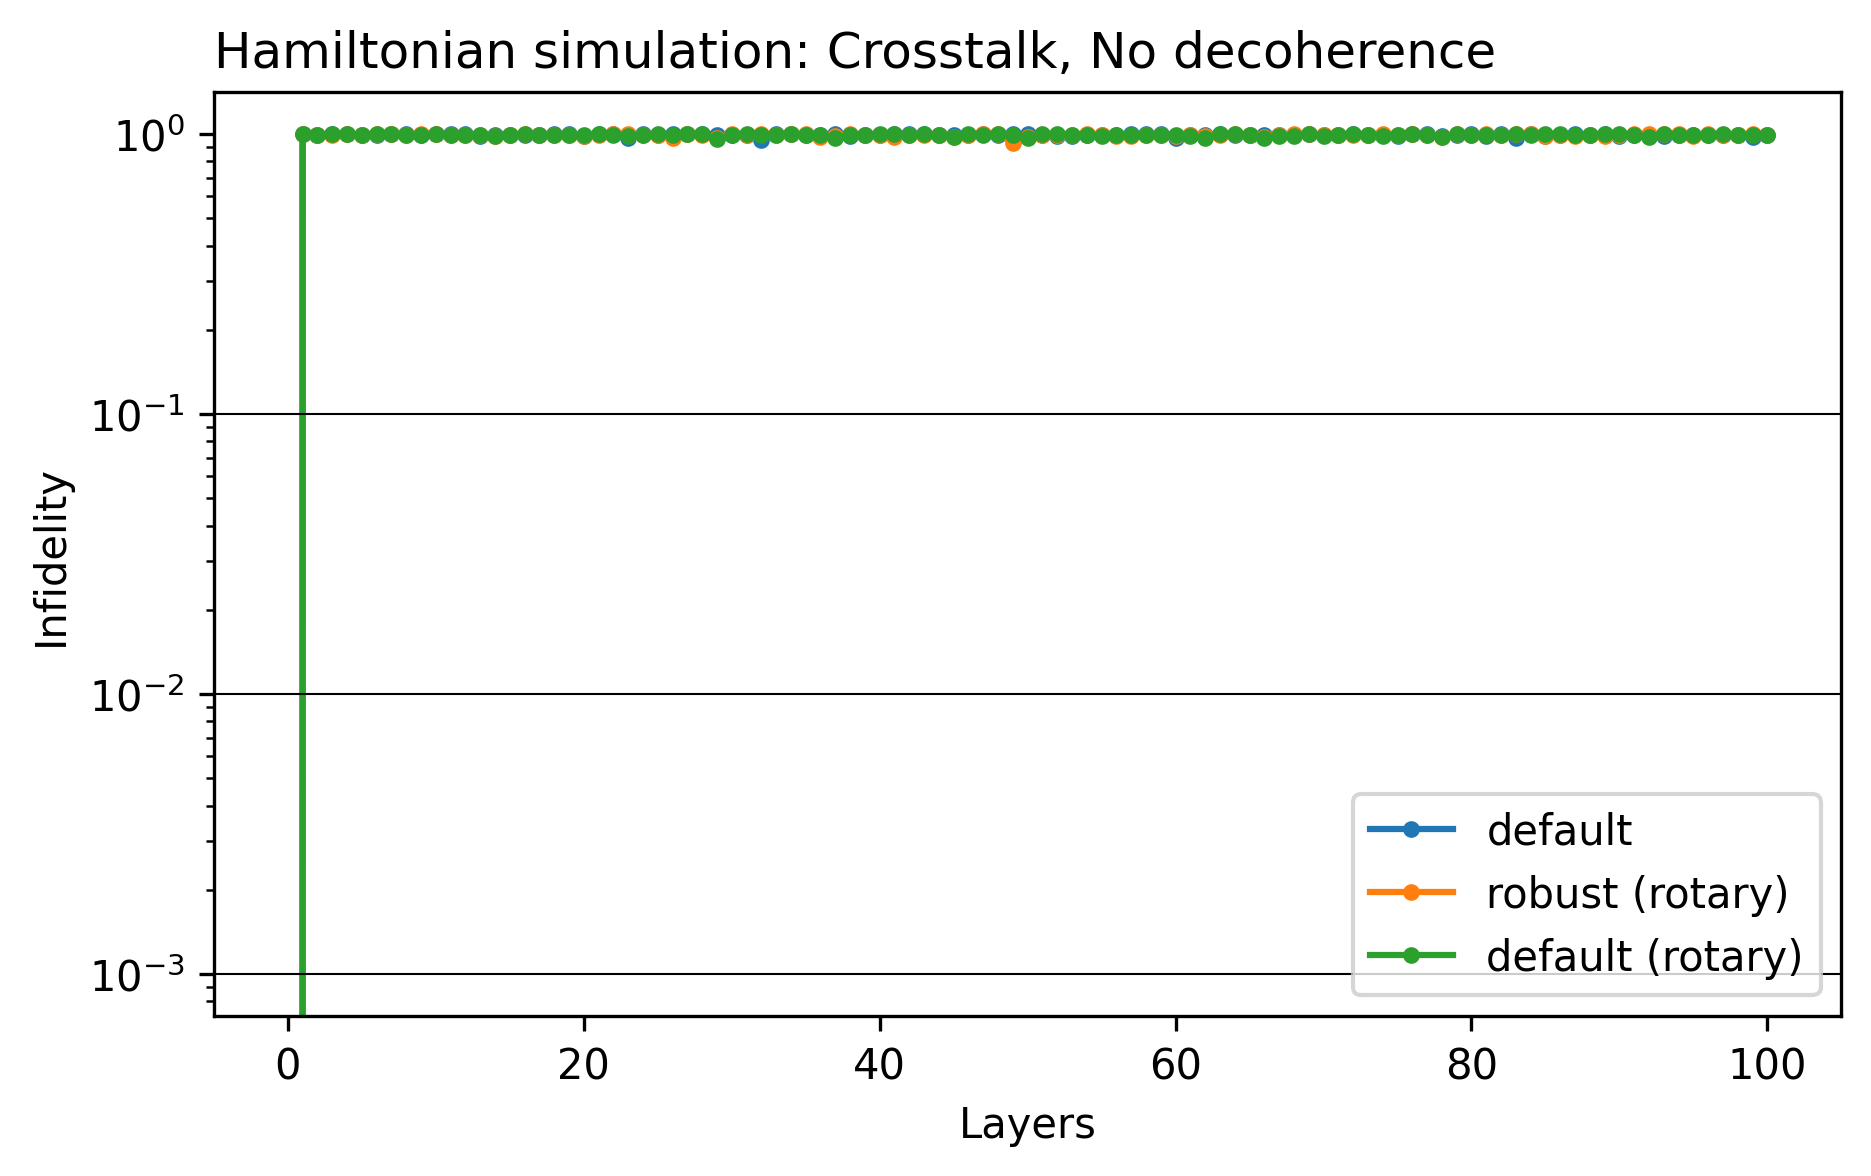

In [51]:
n = 100

fig, axes = plt.subplots(1, figsize=[7, 4], dpi=300)
axes = axes if isinstance(axes, np.ndarray) else [axes]
# fig.suptitle("Hamiltonian simulation")
axes[0].set_title("Hamiltonian simulation: Crosstalk, No decoherence", loc='left')

# NOTE: Manually add a layer 0 for the initial state
layers = np.arange(0, n + 1)
Ulayers = list(itertools.accumulate(np.repeat([target], n, axis=0), np.matmul))

for iax in range(1):
    ax = axes[iax]

    for i, res in enumerate(res_x0):
        # if labels[i] == "default":
        #     continue

        Ufs = itertools.accumulate(np.repeat([res.y[-1]], n, axis=0), np.matmul)
        infids = [0]
        for u, t in zip(Ufs, Ulayers):
            infids.append(1 - qk.quantum_info.process_fidelity(qk.quantum_info.Operator(u), qk.quantum_info.Operator(t)))
        # Labels set previously
        ax.plot(layers, infids, label=labels[i], marker=".")

    ax.axhline(0.1, color="black", linestyle="-", lw=0.5)
    ax.axhline(0.01, color="black", linestyle="-", lw=0.5)
    ax.axhline(0.001, color="black", linestyle="-", lw=0.5)

    ax.set_xlabel("Layers")
    if iax == 0:
        ax.legend(loc="lower right")
        ax.set_yscale("log")
        ax.set_ylabel("Infidelity")
    else:
        ax.set_ylabel("Infidelity")
        ax.legend(loc="upper left")
        ax.set_yscale("linear")

### With decoherence

In [ ]:
print("Case 3: Crosstalk and Decoherence")

# y0 = ps.qiskit_identity_operator(len(registers), open=True)
y0 = ps.qiskit_ground_state(len(registers), open=True)

labels = ["default", "robust (rotary)", "default (rotary)"]
schedules = [sched, robust_sched, mix_sched]

solver_rx.model.evaluation_mode = "sparse_vectorized"
res_x = solver_rx.solve(
    t_span=[0.0, sched.duration * dt],
    t_eval=measure_times,
    y0=y0,
    signals=schedules,
    atol=1e-9,
    rtol=1e-9,
    method="jax_odeint",
)

# Compute fidelity (we can use our circuit to compute the target)
target = qk.quantum_info.Operator(ps.build_circuit(my_moments, registers))
y_target = y0.evolve(target)

# for i in range(len(res_x)):
#     print(
#         f"\tInfidelity of {labels[i]} schedule: {1 - qk.quantum_info.process_fidelity(res_x[0].y[-1], target)}"
#     )

for i in range(len(res_x)):
    print(
        f"\tInfidelity of {labels[i]} schedule: {1 - qk.quantum_info.state_fidelity(res_x[i].y[-1], y_target)}"
    )

Case 3: Crosstalk and Decoherence


In [ ]:
print("Case 3.5: Decoherence")

# y0 = ps.qiskit_identity_operator(len(registers), open=True)
y0 = ps.qiskit_ground_state(len(registers), open=True)

labels = ["decoherence limit, default", "decoherence limit, robust (rotary)", "decoherence limit, default (rotary)"]
schedules = [sched, robust_sched, mix_sched]

solver_r.model.evaluation_mode = "dense"
res_r = solver_r.solve(
    t_span=[0.0, sched.duration * dt],
    t_eval=measure_times,
    y0=y0,
    signals=schedules,
    atol=1e-9,
    rtol=1e-9,
    method="jax_odeint",
)

# Compute fidelity (we can use our circuit to compute the target)
target = qk.quantum_info.Operator(ps.build_circuit(my_moments, registers))
y_target = y0.evolve(target)

for i in range(len(res_r)):
    print(
        f"\tInfidelity of {labels[i]} schedule: {1 - qk.quantum_info.state_fidelity(res_r[i].y[-1], y_target)}"
    )

In [ ]:
# Save the results
# format datetime for a file name
now = datetime.now()
dt_string = now.strftime("%Y-%m-%d-%H-%M-%S")
pkl.dump(
    {
        "res_x0": res_x0,
        "res_x": res_x,
        "res_r": res_r,
        "measure_times": measure_times,
        "Uts": Uts,
    },
    open(f"../playground/{dt_string}-scale-{scale}-crosstalk-decoherence.pkl", "wb"),
)

In [ ]:
fig, axes = plt.subplots(1, figsize=[7, 4], dpi=300)
axes = axes if isinstance(axes, np.ndarray) else [axes]
axes[0].set_title("Hamiltonian simulation: Crosstalk and decoherence", loc='left')

yts = [y0.evolve(Ut) for Ut in Uts]
labels = ["default", "robust (rotary)", "default (rotary)"]
# labels = ["decoherence limit, default", "decoherence limit, robust (rotary)", "decoherence limit, default (rotary)"]

for iax in range(len(axes)):
    ax = axes[iax]
    tab10 = plt.get_cmap("tab10")
    for i, (rx, rr) in enumerate(zip(res_x, res_r)):
        infids = [0]
        infids_decoh = [0]
        for j, t in enumerate(yts):
            infids.append(1 - qk.quantum_info.state_fidelity(rx.y[j], t))
            infids_decoh.append(1 - qk.quantum_info.state_fidelity(rr.y[j], t))
        if i == 0:
            ax.plot(np.hstack([0, *measure_times]), infids_decoh, c='k', ls='--',lw=1, zorder=10, label="decoherence limit")
        ax.plot(np.hstack([0, *measure_times]), infids, c=tab10(i), label=labels[i], marker=".")

    ax.axhline(0.1, color="black", linestyle="-", lw=0.5)
    ax.axhline(0.01, color="black", linestyle="-", lw=0.5)
    ax.axhline(0.001, color="black", linestyle="-", lw=0.5)

    ax.set_xlabel("Time")
    if iax == 0:
        ax.legend(loc="lower right")
        ax.set_yscale("log")
        ax.set_ylabel("Infidelity")
    else:
        ax.set_ylabel("Infidelity")
        ax.legend(loc="upper left")
        ax.set_yscale("linear")

# Combo plot

In [ ]:
# Load from file
two_res_x0 = []
two_res_x = []
two_res_r = []
with open("../playground/2024-03-01-15-06-33-scale-10-crosstalk-decoherence.pkl", "rb") as f:
    data = pkl.load(f)
    two_res_x0.append(data['res_x0'])
    two_res_x.append(data['res_x'])
    two_res_r.append(data['res_r'])

with open("../playground/2024-03-01-15-36-13-scale-1.0-crosstalk-decoherence.pkl", "rb") as f:
    data = pkl.load(f)
    two_res_x0.append(data['res_x0'])
    two_res_x.append(data['res_x'])
    two_res_r.append(data['res_r'])

In [ ]:
fig, axes = plt.subplots(1, figsize=[7, 4], dpi=300)
axes = axes if isinstance(axes, np.ndarray) else [axes]
# axes[0].set_title("Hamiltonian simulation: Crosstalk, No decoherence", loc='left')


for iax in range(1):
    ax = axes[iax]
    for i in range(len(labels)):
        res1 = two_res_x0[0][i]
        res2 = two_res_x0[1][i]
        infids1 = [0]
        infids2 = [0]
        for r1, r2, t in zip(res1.y, res2.y, Uts):
            infids1.append(1 - qk.quantum_info.process_fidelity(qk.quantum_info.Operator(r1), qk.quantum_info.Operator(t)))
            infids2.append(1 - qk.quantum_info.process_fidelity(qk.quantum_info.Operator(r2), qk.quantum_info.Operator(t)))
    
        x = np.hstack([0, *measure_times])
        ax.fill_between(x, y1=infids1, y2=infids2, color=tab10(i), alpha=0.33)
        ax.plot(x, infids1, label=labels[i], marker=".", color=tab10(i))
        ax.plot(x, infids2, marker=".", color=tab10(i))

    ax.axhline(0.1, color="black", linestyle="-", lw=0.5)
    ax.axhline(0.01, color="black", linestyle="-", lw=0.5)
    ax.axhline(0.001, color="black", linestyle="-", lw=0.5)
    ax.axhline(0.0001, color="black", linestyle="-", lw=0.5)

    ax.set_xlabel("Time")
    if iax == 0:
        ax.legend(loc="lower right")
        ax.set_yscale("log")
        ax.set_ylabel("Infidelity")
    else:
        ax.set_ylabel("Infidelity")
        ax.legend(loc="upper left")
        ax.set_yscale("linear")

In [ ]:
fig, axes = plt.subplots(1, figsize=[7, 4], dpi=300)
axes = axes if isinstance(axes, np.ndarray) else [axes]
axes[0].set_title("Hamiltonian simulation: Crosstalk and decoherence", loc='left')

yts = [y0.evolve(Ut) for Ut in Uts]
labels = ["default", "robust (rotary)", "default (rotary)"]
# labels = ["decoherence limit, default", "decoherence limit, robust (rotary)", "decoherence limit, default (rotary)"]

for iax in range(len(axes)):
    ax = axes[iax]
    tab10 = plt.get_cmap("tab10")
    for i in range(len(labels)):

        infids1 = [0]
        infids2 = [0]
        infids_decoh = [0]
        for j, t in enumerate(yts):
            infids1.append(1 - qk.quantum_info.state_fidelity(two_res_x[0][i].y[j], t))
            infids2.append(1 - qk.quantum_info.state_fidelity(two_res_x[1][i].y[j], t))
            infids_decoh.append(1 - qk.quantum_info.state_fidelity(rr.y[j], t))
        if i == 0:
            ax.plot(np.hstack([0, *measure_times]), infids_decoh, c='k', ls='--',lw=1, zorder=10, label="decoherence limit")
        x = np.hstack([0, *measure_times])
        ax.fill_between(x, y1=infids1, y2=infids2, color=tab10(i), alpha=0.33)
        ax.plot(x, infids1, label=labels[i], marker=".", color=tab10(i))
        ax.plot(x, infids2, marker=".", color=tab10(i))

    ax.axhline(0.1, color="black", linestyle="-", lw=0.5)
    ax.axhline(0.01, color="black", linestyle="-", lw=0.5)
    ax.axhline(0.001, color="black", linestyle="-", lw=0.5)

    ax.set_xlabel("Time")
    if iax == 0:
        ax.legend(loc="lower right")
        ax.set_yscale("log")
        ax.set_ylabel("Infidelity")
    else:
        ax.set_ylabel("Infidelity")
        ax.legend(loc="upper left")
        ax.set_yscale("linear")